In [34]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


## Load The Dataset

In [35]:
fd = pd.read_csv('Daily Household Transactions.csv') ##fd means financial dashboard

## See the First 5 rows


In [36]:
fd.head()

,Date,Mode,Category,Subcategory,Note,Amount,Income/Expense,Currency
0,20/09/2018 12:04:08,Cash,Transportation,Train,2 Place 5 to Place 0,30.0,Expense,INR
1,20/09/2018 12:03:15,Cash,Food,snacks,Idli medu Vada mix 2 plates,60.0,Expense,INR
2,19/09/2018,Saving Bank account 1,subscription,Netflix,1 month subscription,199.0,Expense,INR
3,17/09/2018 23:41:17,Saving Bank account 1,subscription,Mobile Service Provider,Data booster pack,19.0,Expense,INR
4,16/09/2018 17:15:08,Cash,Festivals,Ganesh Pujan,Ganesh idol,251.0,Expense,INR


## See the Last 5 rows

In [37]:
fd.tail()

,Date,Mode,Category,Subcategory,Note,Amount,Income/Expense,Currency
2456,1/1/2015,Cash,Transportation,NaN,share jeep - Place T base to top,20.0,Expense,INR
2457,1/1/2015,Cash,Transportation,NaN,share auto - Place H to Place T base,20.0,Expense,INR
2458,1/1/2015,Cash,Transportation,NaN,bus - brc to Place H,30.0,Expense,INR
2459,1/1/2015,Cash,Food,NaN,tea,10.0,Expense,INR
2460,1/1/2015,Cash,Transportation,NaN,share auto - hospital to brc station,10.0,Expense,INR


## Dataset Shape

In [38]:
fd.shape

(2461, 8)

There are 10806 rowns and 7 columns

## Dataset columns

In [39]:
print("Columns:", fd.columns.tolist())

Columns: ['Date', 'Mode', 'Category', 'Subcategory', 'Note', 'Amount', 'Income/Expense', 'Currency']


## Dataset Data Type

In [40]:
fd.dtypes

Date               object
Mode               object
Category           object
Subcategory        object
Note               object
Amount            float64
Income/Expense     object
Currency           object
dtype: object

## Dataset Info

In [41]:
fd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2461 entries, 0 to 2460
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Date            2461 non-null   object 
 1   Mode            2461 non-null   object 
 2   Category        2461 non-null   object 
 3   Subcategory     1826 non-null   object 
 4   Note            1940 non-null   object 
 5   Amount          2461 non-null   float64
 6   Income/Expense  2461 non-null   object 
 7   Currency        2461 non-null   object 
dtypes: float64(1), object(7)
memory usage: 153.9+ KB


## Statistical Analysis

In [42]:
fd.describe()

,Amount
count,2461.000000
mean,2751.145380
std,12519.615804
min,2.000000
25%,35.000000
50%,100.000000
75%,799.000000
max,250000.000000


## Missing Values Analysis

In [43]:
fd.isnull().sum()

Date                0
Mode                0
Category            0
Subcategory       635
Note              521
Amount              0
Income/Expense      0
Currency            0
dtype: int64

## Handle The missing Values

In [44]:
# Handle missing values
fd["Subcategory"] = fd["Subcategory"].fillna("Not Specified")

fd["Note"] = fd["Note"].fillna("No Note")

# Verify
fd.isnull().sum()


Date              0
Mode              0
Category          0
Subcategory       0
Note              0
Amount            0
Income/Expense    0
Currency          0
dtype: int64

## Duplicate Value Check


In [45]:
fd.duplicated().sum()

np.int64(9)

There are 9 duplicat values present in this dataset

In [46]:
## handle the duplicate values
fd = fd.drop_duplicates()
print("After removing duplicates, the shape of the DataFrame is:", fd.shape)

After removing duplicates, the shape of the DataFrame is: (2452, 8)


## Convert Data Types

In [47]:
fd["Date"] = pd.to_datetime(fd["Date"],format="mixed",dayfirst=True,errors="coerce")
# Convert Amount column
fd["Amount"] = pd.to_numeric(fd["Amount"],errors="coerce")
# Check data types
fd.dtypes


Date              datetime64[ns]
Mode                      object
Category                  object
Subcategory               object
Note                      object
Amount                   float64
Income/Expense            object
Currency                  object
dtype: object

## Validate Conversion

In [48]:
print("Invalid Dates:", fd["Date"].isnull().sum())
print("Invalid Amounts:", fd["Amount"].isnull().sum())

print("\nTransaction Types:")
print(fd["Income/Expense"].value_counts())

print("\nCurrencies:")
print(fd["Currency"].value_counts())

Invalid Dates: 0
Invalid Amounts: 0

Transaction Types:
Income/Expense
Expense         2173
Transfer-Out     154
Income           125
Name: count, dtype: int64

Currencies:
Currency
INR    2452
Name: count, dtype: int64


## Date-Based Feature Engineering

In [49]:
# Date Feature Engineering

fd["Year"] = fd["Date"].dt.year
fd["Month"] = fd["Date"].dt.month
fd["Month_Name"] = fd["Date"].dt.month_name()
fd["Day"] = fd["Date"].dt.day
fd["Day_of_Week"] = fd["Date"].dt.day_name()

fd["Year_Month"] = fd["Date"].dt.to_period("M")

# Check new features
fd.head()


,Date,Mode,Category,Subcategory,Note,Amount,Income/Expense,Currency,Year,Month,Month_Name,Day,Day_of_Week,Year_Month
0,2018-09-20 12:04:08,Cash,Transportation,Train,2 Place 5 to Place 0,30.0,Expense,INR,2018,9,September,20,Thursday,2018-09
1,2018-09-20 12:03:15,Cash,Food,snacks,Idli medu Vada mix 2 plates,60.0,Expense,INR,2018,9,September,20,Thursday,2018-09
2,2018-09-19 00:00:00,Saving Bank account 1,subscription,Netflix,1 month subscription,199.0,Expense,INR,2018,9,September,19,Wednesday,2018-09
3,2018-09-17 23:41:17,Saving Bank account 1,subscription,Mobile Service Provider,Data booster pack,19.0,Expense,INR,2018,9,September,17,Monday,2018-09
4,2018-09-16 17:15:08,Cash,Festivals,Ganesh Pujan,Ganesh idol,251.0,Expense,INR,2018,9,September,16,Sunday,2018-09


## Verify Features

In [50]:
print("Total Columns:", fd.shape[1])

print("\nDate Range:")
print("Start:", fd["Date"].min())
print("End:", fd["Date"].max())

print("\nMissing Values in New Features:")
print(
    fd[["Year", "Month", "Day", "Year_Month"]]
    .isnull().sum()
)

Total Columns: 14

Date Range:
Start: 2015-01-01 00:00:00
End: 2018-09-20 12:04:08

Missing Values in New Features:
Year          0
Month         0
Day           0
Year_Month    0
dtype: int64


## `Transaction Type Analysis`

In [51]:
# Transaction Type Analysis

transaction_summary = fd.groupby("Income/Expense")["Amount"].agg(["count", "sum", "mean"]).round(2)

transaction_summary


,count,sum,mean
Income/Expense,,,
Expense,2173,1955380.53,899.85
Income,125,3042397.35,24339.18
Transfer-Out,154,1764780.90,11459.62


## `Financial KPI Calculation`

In [52]:
# Financial Dashboard - KPI Analysis

# 1. Total Income
total_income = fd.loc[fd["Income/Expense"] == "Income", "Amount"].sum()

# 2. Total Expense
total_expense = fd.loc[fd["Income/Expense"] == "Expense", "Amount"].sum()

# 3. Total Transfer-Out
total_transfer = fd.loc[fd["Income/Expense"] == "Transfer-Out", "Amount"].sum()

# 4. Net Surplus
net_surplus = total_income - total_expense

# 5. Savings Potential Rate
savings_rate = (net_surplus / total_income) * 100 if total_income > 0 else 0

# 6. Expense-to-Income Ratio
expense_ratio = (total_expense / total_income) * 100 if total_income > 0 else 0

# 7. Average Monthly Expense
total_months = fd["Year_Month"].nunique()
avg_monthly_expense = total_expense / total_months if total_months > 0 else 0

# 8. Average Expense Transaction
avg_transaction = fd.loc[fd["Income/Expense"] == "Expense", "Amount"].mean()

# Display Results
print("========== FINANCIAL DASHBOARD KPIs ==========")

print("Total Income:", round(total_income, 2))
print("Total Expense:", round(total_expense, 2))
print("Total Transfer-Out:", round(total_transfer, 2))
print("Net Surplus:", round(net_surplus, 2))

print("\n========== FINANCIAL RATIOS ==========")

print("Savings Potential Rate:", round(savings_rate, 2), "%")
print("Expense-to-Income Ratio:", round(expense_ratio, 2), "%")
print("Average Monthly Expense:", round(avg_monthly_expense, 2))
print("Average Expense Transaction:", round(avg_transaction, 2))


========== FINANCIAL DASHBOARD KPIs ==========
Total Income: 3042397.35
Total Expense: 1955380.53
Total Transfer-Out: 1764780.9
Net Surplus: 1087016.82

========== FINANCIAL RATIOS ==========
Savings Potential Rate: 35.73 %
Expense-to-Income Ratio: 64.27 %
Average Monthly Expense: 43452.9
Average Expense Transaction: 899.85


## Category-wise Expense Analysis

In [53]:
# Filter Expense Transactions
expense_df = fd[fd["Income/Expense"] == "Expense"].copy()

# Category-wise Expense Analysis
category_expense = expense_df.groupby("Category")["Amount"].agg(Total_Expense="sum",Transactions="count",Average_Expense="mean").round(2)

# Calculate Expense Percentage
category_expense["Expense_Percentage"] = (category_expense["Total_Expense"] / total_expense * 100).round(2)
# Sort by highest expense
category_expense = category_expense.sort_values(by="Total_Expense",ascending=False)

category_expense


,Total_Expense,Transactions,Average_Expense,Expense_Percentage
Category,,,,
Money transfer,606528.90,43,14105.32,31.02
Investment,269858.00,101,2671.86,13.80
Transportation,169053.78,307,550.66,8.65
Household,161645.58,176,918.44,8.27
subscription,114587.91,143,801.31,5.86
Food,96393.10,906,106.39,4.93
Public Provident Fund,90000.00,8,11250.00,4.60
Other,87025.28,114,763.38,4.45
Family,78582.20,71,1106.79,4.02


##  Highest Spending Category

In [54]:
# Highest Spending Category
highest_category = category_expense.index[0]

highest_amount = category_expense.iloc[0]["Total_Expense"]

highest_percentage = category_expense.iloc[0]["Expense_Percentage"]

print("Highest Spending Category:", highest_category)
print("Total Spending:", round(highest_amount, 2))
print("Percentage of Total Expense:", round(highest_percentage, 2), "%")


Highest Spending Category: Money transfer
Total Spending: 606528.9
Percentage of Total Expense: 31.02 %


## Transaction Category Validation

In [55]:
selected_categories = [
    "Money transfer",
    "Investment",
    "Public Provident Fund",
    "Recurring Deposit"
]

check_df = fd[
    (fd["Income/Expense"] == "Expense") &
    (fd["Category"].isin(selected_categories))
]

# Subcategory Analysis
display(
    check_df.groupby(
        ["Category", "Subcategory"],
        dropna=False
    )["Amount"].agg(["count", "sum"])
)

# Check transaction details
display(
    check_df[
        ["Category", "Subcategory", "Note", "Amount"]
    ].head(20)
)


count       sum
Category              Subcategory                           
Investment            LIC                        3   33858.0
                      Mutual fund               64   64000.0
                      Public Provident Fund     12  150000.0
                      RD                        22   22000.0
Money transfer        Home                      15  204505.9
                      Not Specified             28  402023.0
Public Provident Fund Not Specified              8   90000.0
Recurring Deposit     Not Specified             22   22000.0

,Category,Subcategory,Note,Amount
102,Money transfer,Home,No Note,30000.0
191,Money transfer,Home,No Note,10000.0
315,Money transfer,Home,No Note,10000.0
376,Money transfer,Home,No Note,24500.0
394,Money transfer,Home,No Note,10005.9
488,Money transfer,Home,No Note,10000.0
567,Money transfer,Home,No Note,10000.0
672,Money transfer,Home,No Note,30000.0
772,Money transfer,Home,No Note,10000.0
870,Money transfer,Home,No Note,10000.0


## Financial Transaction Classification

In [56]:

# Create Dashboard Group
fd["Dashboard_Group"] = "Other Transaction"

# Income
fd.loc[
    fd["Income/Expense"] == "Income",
    "Dashboard_Group"
] = "Income"

# Regular Expenses
fd.loc[
    fd["Income/Expense"] == "Expense",
    "Dashboard_Group"
] = "Regular Expenses"

# Investment and Savings
fd.loc[
    (fd["Income/Expense"] == "Expense") &
    (fd["Category"].isin([
        "Investment",
        "Public Provident Fund",
        "Recurring Deposit"
    ])),
    "Dashboard_Group"
] = "Investment & Savings"

# Money Transfer (Unverified)
fd.loc[
    (fd["Income/Expense"] == "Expense") &
    (fd["Category"] == "Money transfer"),
    "Dashboard_Group"
] = "Money Transfer - Review"

# Transfer-Out
fd.loc[
    fd["Income/Expense"] == "Transfer-Out",
    "Dashboard_Group"
] = "Transfer-Out"

# Group-wise Financial Summary
group_summary = fd.groupby("Dashboard_Group")["Amount"].agg(
    ["count", "sum"]
).round(2)

group_summary


,count,sum
Dashboard_Group,,
Income,125,3042397.35
Investment & Savings,131,381858.00
Money Transfer - Review,43,606528.90
Regular Expenses,1999,966993.63
Transfer-Out,154,1764780.90


## Advanced Financial KPI Calculation

In [57]:
# Group-wise Amounts
kpi = fd.groupby("Dashboard_Group")["Amount"].sum()

income = kpi.get("Income", 0)
regular_expense = kpi.get("Regular Expenses", 0)
investments = kpi.get("Investment & Savings", 0)
money_transfer = kpi.get("Money Transfer - Review", 0)
transfer_out = kpi.get("Transfer-Out", 0)

# Financial Calculations
total_outflow = (
    regular_expense + investments
    + money_transfer + transfer_out
)

recorded_net_flow = income - total_outflow

expense_ratio = (
    regular_expense / income * 100
    if income > 0 else 0
)

investment_ratio = (
    investments / income * 100
    if income > 0 else 0
)

# Display KPIs
print("========== ADVANCED FINANCIAL KPIs ==========")

print("Total Income:", round(income, 2))
print("Regular Expenses:", round(regular_expense, 2))
print("Investment & Savings Contributions:", round(investments, 2))
print("Money Transfer - Review:", round(money_transfer, 2))
print("Transfer-Out:", round(transfer_out, 2))
print("Total Recorded Outflow:", round(total_outflow, 2))
print("Recorded Net Flow:", round(recorded_net_flow, 2))

print("\n========== FINANCIAL RATIOS ==========")

print("Regular Expense Ratio:", round(expense_ratio, 2), "%")
print("Investment Contribution Ratio:", round(investment_ratio, 2), "%")


========== ADVANCED FINANCIAL KPIs ==========
Total Income: 3042397.35
Regular Expenses: 966993.63
Investment & Savings Contributions: 381858.0
Money Transfer - Review: 606528.9
Transfer-Out: 1764780.9
Total Recorded Outflow: 3720161.43
Recorded Net Flow: -677764.08

========== FINANCIAL RATIOS ==========
Regular Expense Ratio: 31.78 %
Investment Contribution Ratio: 12.55 %


## Monthly Financial Summary

In [58]:

# Monthly Financial Analysis

monthly_finance = fd.pivot_table(
    index="Year_Month",
    columns="Dashboard_Group",
    values="Amount",
    aggfunc="sum",
    fill_value=0
)

# Ensure all financial groups are included
groups = [
    "Income",
    "Regular Expenses",
    "Investment & Savings",
    "Money Transfer - Review",
    "Transfer-Out"
]

monthly_finance = monthly_finance.reindex(
    columns=groups,
    fill_value=0
)

# Calculate Monthly Outflow
monthly_finance["Total_Outflow"] = (
    monthly_finance["Regular Expenses"]
    + monthly_finance["Investment & Savings"]
    + monthly_finance["Money Transfer - Review"]
    + monthly_finance["Transfer-Out"]
)

# Calculate Monthly Recorded Net Flow
monthly_finance["Net_Flow"] = (
    monthly_finance["Income"]
    - monthly_finance["Total_Outflow"]
)

# Sort chronologically
monthly_finance = monthly_finance.sort_index()

monthly_finance.round(2).head(10)


Dashboard_Group,Income,Regular Expenses,Investment & Savings,Money Transfer - Review,Transfer-Out,Total_Outflow,Net_Flow
Year_Month,,,,,,,
2015-01,0.0,33870.0,0.0,0.0,0.0,33870.0,-33870.0
2015-02,49806.0,24308.0,0.0,0.0,0.0,24308.0,25498.0
2015-03,70806.0,17631.4,5000.0,10000.0,0.0,32631.4,38174.6
2015-04,49306.0,9222.0,5000.0,10000.0,0.0,24222.0,25084.0
2015-05,47859.0,18118.0,25000.0,20000.0,0.0,63118.0,-15259.0
2015-06,47859.0,4567.0,15000.0,0.0,0.0,19567.0,28292.0
2015-07,47859.0,6735.0,15000.0,10000.0,0.0,31735.0,16124.0
2015-08,49806.0,8340.0,15000.0,20000.0,0.0,43340.0,6466.0
2015-09,54606.0,3577.0,15000.0,0.0,0.0,18577.0,36029.0


## Monthly Financial Verification

In [59]:
print("Total Months:", len(monthly_finance))

print("\nTotal Monthly Income:",
      round(monthly_finance["Income"].sum(), 2))

print("Total Monthly Outflow:",
      round(monthly_finance["Total_Outflow"].sum(), 2))

print("Total Monthly Net Flow:",
      round(monthly_finance["Net_Flow"].sum(), 2))

Total Months: 45

Total Monthly Income: 3042397.35
Total Monthly Outflow: 3720161.43
Total Monthly Net Flow: -677764.08


## Advanced Date Features

In [60]:
# Advanced Date Features

fd["Quarter"] = fd["Date"].dt.quarter

fd["Year_Quarter"] = fd["Date"].dt.to_period("Q")

fd["Week_of_Year"] = fd["Date"].dt.isocalendar().week.astype(int)

fd["Is_Weekend"] = fd["Date"].dt.dayofweek.isin([5, 6]).astype(int)

fd["Is_Month_Start"] = fd["Date"].dt.is_month_start.astype(int)

fd["Is_Month_End"] = fd["Date"].dt.is_month_end.astype(int)

fd.head()


,Date,Mode,Category,Subcategory,Note,Amount,Income/Expense,Currency,Year,Month,...,Day,Day_of_Week,Year_Month,Dashboard_Group,Quarter,Year_Quarter,Week_of_Year,Is_Weekend,Is_Month_Start,Is_Month_End
0,2018-09-20 12:04:08,Cash,Transportation,Train,2 Place 5 to Place 0,30.0,Expense,INR,2018,9,...,20,Thursday,2018-09,Regular Expenses,3,2018Q3,38,0,0,0
1,2018-09-20 12:03:15,Cash,Food,snacks,Idli medu Vada mix 2 plates,60.0,Expense,INR,2018,9,...,20,Thursday,2018-09,Regular Expenses,3,2018Q3,38,0,0,0
2,2018-09-19 00:00:00,Saving Bank account 1,subscription,Netflix,1 month subscription,199.0,Expense,INR,2018,9,...,19,Wednesday,2018-09,Regular Expenses,3,2018Q3,38,0,0,0
3,2018-09-17 23:41:17,Saving Bank account 1,subscription,Mobile Service Provider,Data booster pack,19.0,Expense,INR,2018,9,...,17,Monday,2018-09,Regular Expenses,3,2018Q3,38,0,0,0
4,2018-09-16 17:15:08,Cash,Festivals,Ganesh Pujan,Ganesh idol,251.0,Expense,INR,2018,9,...,16,Sunday,2018-09,Regular Expenses,3,2018Q3,37,1,0,0


## Recurring Transaction Features

In [61]:
# Count earlier months with same transaction pattern

fd["Prior_Months_Seen"] = (fd.groupby(["Category", "Subcategory", "Amount"])["Year_Month"].rank(method="dense").astype(int) - 1)


# Identify possible recurring payments
recurring_categories = ["subscription","rent","maid"]
fd["Recurring_Candidate"] = ((fd["Income/Expense"] == "Expense") &(fd["Category"].str.lower().str.strip().isin(recurring_categories)) &(fd["Prior_Months_Seen"] >= 2)).astype(int)
print("Possible Recurring Transactions:")
print(fd["Recurring_Candidate"].value_counts())


Possible Recurring Transactions:
Recurring_Candidate
0    2390
1      62
Name: count, dtype: int64


## Quarterly Financial Analysis

In [62]:
# Quarterly Financial Summary

quarterly_finance = fd.pivot_table(
    index="Year_Quarter",
    columns="Dashboard_Group",
    values="Amount",
    aggfunc="sum",
    fill_value=0
)

quarterly_finance = quarterly_finance.sort_index()

quarterly_finance.head()


Dashboard_Group,Income,Investment & Savings,Money Transfer - Review,Regular Expenses,Transfer-Out
Year_Quarter,,,,,
2015Q1,120612.0,5000.0,10000.0,75809.4,0.0
2015Q2,145024.0,45000.0,30000.0,31907.0,0.0
2015Q3,152271.0,45000.0,30000.0,18652.0,0.0
2015Q4,178447.0,45000.0,62000.0,23706.0,0.0
2016Q1,215418.0,45000.0,30000.0,7087.0,0.0


## Spending Trend & Historical Features

In [63]:
# Historical Financial Features

monthly_finance = monthly_finance.sort_index()

# Previous Month Income
monthly_finance["Income_Lag_1M"] = (monthly_finance["Income"].shift(1))

# Previous Month Expense
monthly_finance["Expense_Lag_1M"] = (monthly_finance["Regular Expenses"].shift(1))

# Average Expense of Previous 3 Months
monthly_finance["Expense_Rolling_3M"] = ( monthly_finance["Regular Expenses"].shift(1).rolling(window=3, min_periods=3).mean())

# Month-over-Month Expense Change
previous_expense = monthly_finance["Regular Expenses"].shift(1)

monthly_finance["Expense_Change_Pct"] = ((monthly_finance["Regular Expenses"] - previous_expense)/ previous_expense.replace(0, float("nan"))) * 100
monthly_finance.tail(10).round(2)


Dashboard_Group,Income,Regular Expenses,Investment & Savings,Money Transfer - Review,Transfer-Out,Total_Outflow,Net_Flow,Income_Lag_1M,Expense_Lag_1M,Expense_Rolling_3M,Expense_Change_Pct
Year_Month,,,,,,,,,,,
2017-12,82321.00,46805.00,0.0,0.0,547108.96,593913.96,-511592.96,143155.00,44364.00,34105.03,5.50
2018-01,292938.00,112080.90,0.0,30000.0,94097.14,236178.04,56759.96,82321.00,46805.00,42233.70,139.46
2018-02,64738.00,16218.00,0.0,10000.0,91704.00,117922.00,-53184.00,292938.00,112080.90,67749.97,-85.53
2018-03,69343.50,13396.75,0.0,10000.0,23042.88,46439.63,22903.87,64738.00,16218.00,58367.97,-17.40
2018-04,65824.15,13833.68,0.0,34505.9,25500.00,73839.58,-8015.43,69343.50,13396.75,47231.88,3.26
2018-05,69238.00,30670.00,0.0,10000.0,36543.00,77213.00,-7975.00,65824.15,13833.68,14482.81,121.71
2018-06,68551.00,38161.02,0.0,0.0,36549.59,74710.61,-6159.61,69238.00,30670.00,19300.14,24.42
2018-07,77267.50,27738.36,0.0,40000.0,25500.00,93238.36,-15970.86,68551.00,38161.02,27554.90,-27.31
2018-08,71735.75,21305.65,0.0,0.0,36543.00,57848.65,13887.10,77267.50,27738.36,32189.79,-23.19


## Visualization

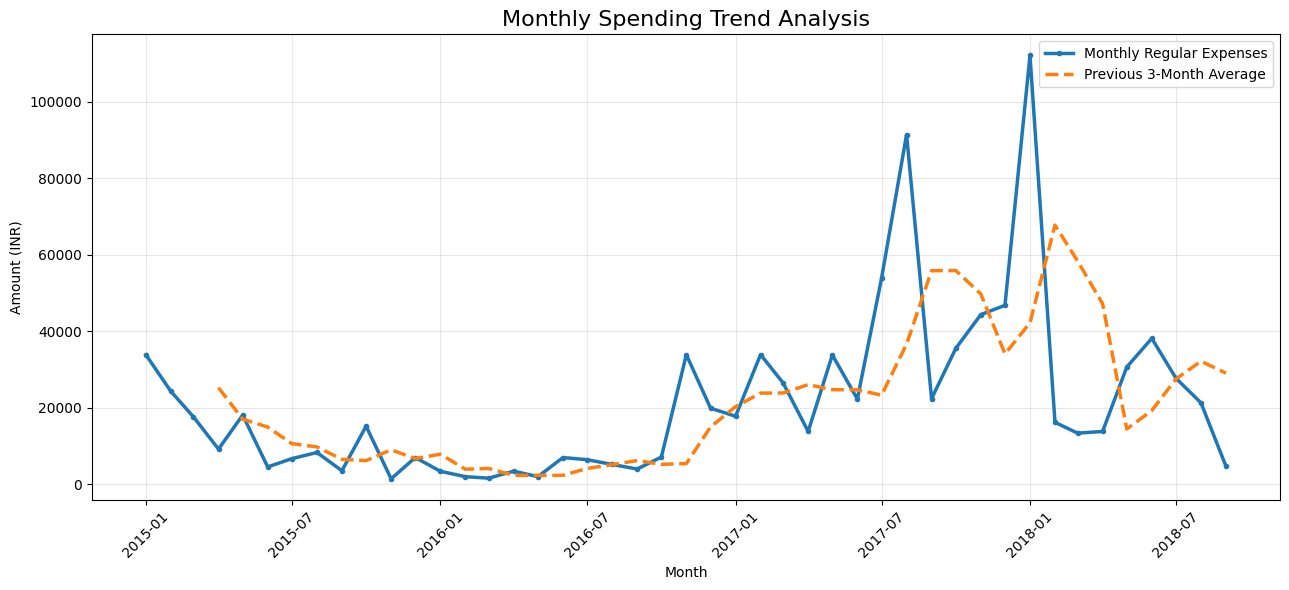

In [64]:
# Monthly dates
months = monthly_finance.index.to_timestamp()

# Detect original dataset currency
currency = fd["Currency"].mode()[0]

plt.figure(figsize=(13, 6))

# Monthly Regular Expenses
plt.plot(
    months,
    monthly_finance["Regular Expenses"],
    label="Monthly Regular Expenses",
    linewidth=2.5,
    marker="o",
    markersize=3
)

# Previous 3-Month Average
plt.plot(
    months,
    monthly_finance["Expense_Rolling_3M"],
    label="Previous 3-Month Average",
    linewidth=2.5,
    linestyle="--"
)

plt.title("Monthly Spending Trend Analysis", fontsize=16)
plt.xlabel("Month")
plt.ylabel(f"Amount ({currency})")

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## Top 10 Spending Categories

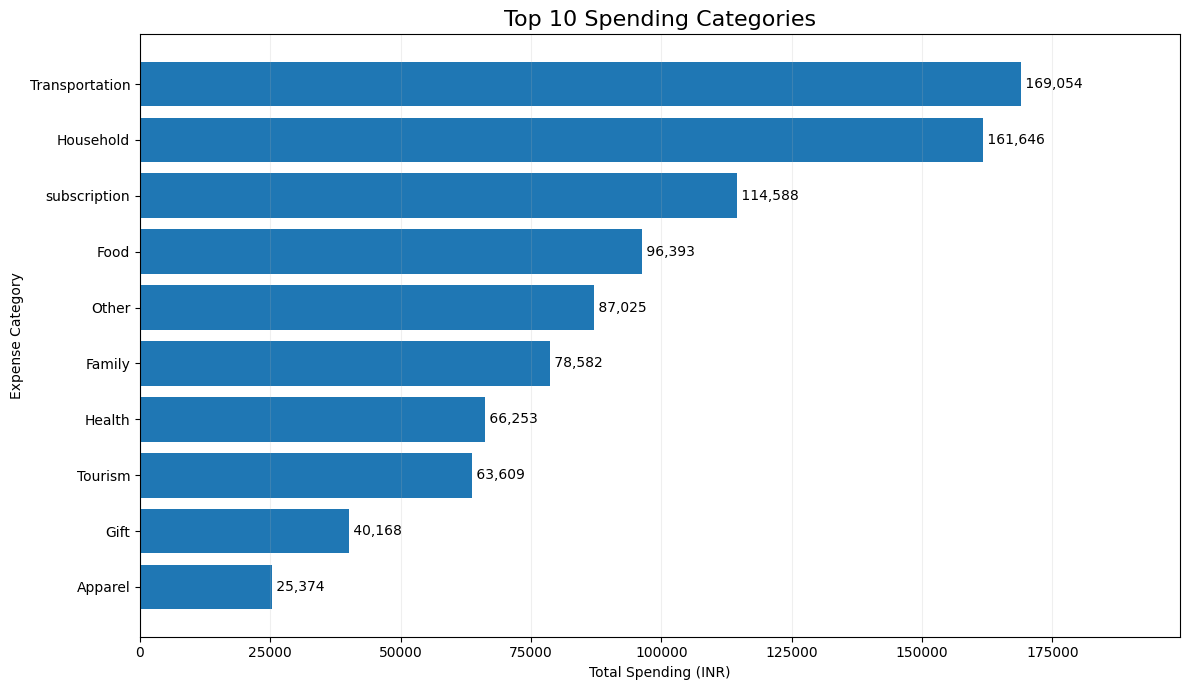

In [65]:
# Filter Regular Expenses
regular_df = fd[fd["Dashboard_Group"] == "Regular Expenses"]

# Category-wise Spending
top_categories = (regular_df.groupby("Category")["Amount"].sum().sort_values(ascending=False).head(10))

# Detect dataset currency
currency = fd["Currency"].mode()[0]

# Create Chart
plt.figure(figsize=(12, 7))

bars = plt.barh(top_categories.index,top_categories.values)

# Highest spending at the top
plt.gca().invert_yaxis()

# Add amount labels
for bar in bars:
    plt.text(
        bar.get_width(),
        bar.get_y() + bar.get_height() / 2,
        f" {bar.get_width():,.0f}",
        va="center",
        fontsize=10
    )

plt.title("Top 10 Spending Categories", fontsize=16)
plt.xlabel(f"Total Spending ({currency})")
plt.ylabel("Expense Category")

plt.xlim(0, top_categories.max() * 1.18)
plt.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()


## Monthly Income vs Expense 

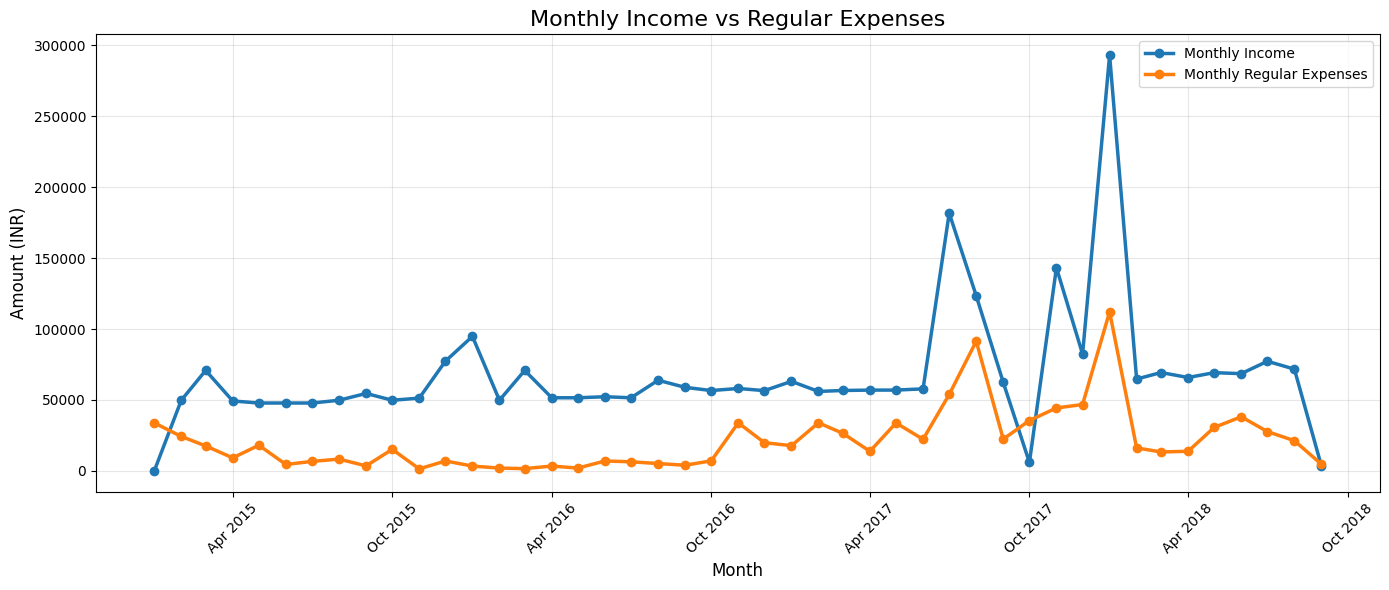

In [66]:

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Monthly Dates
months = monthly_finance.index.to_timestamp()

# Original Dataset Currency
currency = fd["Currency"].mode()[0]

plt.figure(figsize=(14, 6))

# Monthly Income
plt.plot(
    months,
    monthly_finance["Income"],
    label="Monthly Income",
    marker="o",
    linewidth=2.5
)

# Monthly Regular Expenses
plt.plot(
    months,
    monthly_finance["Regular Expenses"],
    label="Monthly Regular Expenses",
    marker="o",
    linewidth=2.5
)

# Chart Formatting
plt.title("Monthly Income vs Regular Expenses", fontsize=16)

plt.xlabel("Month", fontsize=12)
plt.ylabel(f"Amount ({currency})", fontsize=12)

plt.gca().xaxis.set_major_locator(
    mdates.MonthLocator(interval=6)
)

plt.gca().xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)

plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()
